# Project 1: Transactions – Pass 11



## Problem Definition



#### 1. State the business problem.

Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.  Mention which model will be used, if known.



#### Problem Statement:

We want to predict whether or not a future customer will complete a transaction (e.g., a product purchase, loan or bill payment, or subscription retention) based on prior transaction data. Such predictions can help determine higher-risk customers and present incentives to drive future transaction completions and increase sales.

This is a supervised, categorical binary classification problem, where the target data is whether a customer transaction was successful (true or false). To achieve this, it uses a Gaussian Naive Bayes model to make predictions about transaction success.




## Data Collection



Data Collection describes the process by which we obtain the data for use in the project. In this case, our data comes from S3 storage buckets on AWS, which we load into memory (variables) via URLs by passing them to the read_csv function of the pandas python library (more on that soon).

The data comes in two separate (but similar) sets: a small data set, which is not used here but was used in earlier analysis passes; and a larger data set containing the full data available for use in the project. The latter is what we use in this final version of the analysis.

Finally, to store the data in a form we can work with in memory, we use a storage structure called a DataFrame object from the pandas python library. This object allows us to quickly view the data and preview operations on the data without changing it, as well as make updates to the data in a highly intuitive way.

#### 2. Load Pandas, Numpy, and Matplotlib modules

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

#### 3. Load data Train.csv from AWS S3.

In [2]:
# url
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.big.csv'

- Read in the data from .csv using pandas:

In [3]:
# make dataframe
df = pd.read_csv( url )

- Check the dataframe:

In [4]:
# check dataframe
df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049995,1049995,train_1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049996,1049996,train_1049996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049997,1049997,train_1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689
1049998,1049998,train_1049998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


For the full data set, we have 1,050,000 rows and 101 feature columns, var_0 - var_100.

## Data Cleaning



Data Cleaning is the process of preparing the data set for use in analysis. Many data sets contain bad or null (empty) values, which can cause errors when trying to work with the data and use it in code. Cleaning the data involves removing bad (null-containing) columns and/or rows from the set, as well as imputing (replacing via insertion) similar data into fields with missing or unusable values.

Here, to clean the data, we mostly use the pandas drop function included with pandas DataFrame objects, which allow us to drop columns and rows according to conditions we specify, much like SQL WHERE clauses.

#### 4. Examine the data using tools we have used in class. You should be identifying the various columns such as ...

    - target column
    - feature columns
    - identifier columns
    - null columns
    - null rows

    Tools you should be using include, but are not limited to:

    - head
    - tail
    - shape
    - size
    - info
    - describe
    - nunique
    - unique
    - isnull/isna



In [5]:
# define target_col
target_col = 'target'
target_col

'target'

- head

In [6]:
# head
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- tail

In [7]:
# tail
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
1049995,1049995,train_1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049996,1049996,train_1049996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049997,1049997,train_1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689
1049998,1049998,train_1049998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049999,1049999,train_1049999,0.0,2.1828,12.3805,17.5654,NaN,8.1795,NaN,NaN,...,NaN,-12.1108,NaN,10.7608,NaN,NaN,NaN,NaN,NaN,14.1690


- shape

In [8]:
# shape
df.shape

(1050000, 104)

- size

In [9]:
# size
df.size

109200000

- info

In [10]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050000 entries, 0 to 1049999
Columns: 104 entries, Unnamed: 0 to var_100
dtypes: float64(102), int64(1), object(1)
memory usage: 833.1+ MB


- describe

In [11]:
# describe
df.describe()

,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
count,1.050000e+06,180000.000000,180000.000000,180000.000000,180000.000000,0.0,180000.000000,0.0,0.0,180000.000000,...,0.0,180000.000000,0.0,180000.000000,0.0,0.0,0.0,0.0,0.0,180000.000000
mean,5.249995e+05,0.100222,7.440715,15.870166,12.735619,NaN,-0.668334,NaN,NaN,1.190419,...,NaN,-3.294620,NaN,-6.727860,NaN,NaN,NaN,NaN,NaN,14.224538
std,3.031090e+05,0.300297,3.021636,3.010492,4.185923,NaN,5.968300,NaN,NaN,5.169343,...,NaN,7.418545,NaN,8.278554,NaN,NaN,NaN,NaN,NaN,0.171058
min,0.000000e+00,0.000000,-2.691700,6.299300,-1.018500,NaN,-22.748700,NaN,NaN,-15.194000,...,NaN,-29.984000,NaN,-35.211700,NaN,NaN,NaN,NaN,NaN,13.729000
25%,2.624998e+05,0.000000,5.160325,13.830400,9.664675,NaN,-4.997500,NaN,NaN,-2.571400,...,NaN,-8.757925,NaN,-12.835875,NaN,NaN,NaN,NaN,NaN,14.098900
50%,5.249995e+05,0.000000,7.350950,15.934600,12.670700,NaN,-0.560300,NaN,NaN,1.194600,...,NaN,-3.170950,NaN,-6.615100,NaN,NaN,NaN,NaN,NaN,14.226800
75%,7.874992e+05,0.000000,9.511125,18.061425,15.837300,NaN,3.632525,NaN,NaN,5.090450,...,NaN,2.043350,NaN,-0.885250,NaN,NaN,NaN,NaN,NaN,14.361800
max,1.049999e+06,1.000000,16.716500,26.079100,26.997600,NaN,18.855400,NaN,NaN,18.471400,...,NaN,21.236400,NaN,18.105600,NaN,NaN,NaN,NaN,NaN,14.743000


- nunique

In [12]:
# nunique
df.nunique()

,0
Unnamed: 0,1050000
ID_code,1050000
target,2
var_0,89982
var_1,89845
...,...
var_96,0
var_97,0
var_98,0
var_99,0


- unique

In [13]:
# unique
df[target_col].unique()

array([nan,  0.,  1.])

- isnull

In [14]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
var_3,1050000
var_16,1050000
var_12,1050000
var_11,1050000
var_9,1050000
...,...
var_88,870000
var_94,870000
var_100,870000
Unnamed: 0,0


In [15]:
# isnull frequencies
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
var_3,100.000000
var_16,100.000000
var_12,100.000000
var_11,100.000000
var_9,100.000000
...,...
var_88,82.857143
var_94,82.857143
var_100,82.857143
Unnamed: 0,0.000000


In [16]:
# look at unique values in the col-by-col null counts to classify cols
((df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100).unique()

array([100.        ,  82.85714286,   0.        ])

Because only these three count 'classes' exist in the data, we do not have to impute values: columns are either all null, all not-null, or all between, where
the ones between have the same number of nulls, including the target row. This means we either leave a column alone (no nulls), drop the entire column (all nulls), or drop rows where the target is null.

- dtypes

In [17]:
# dtypes
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,float64
var_0,float64
var_1,float64
...,...
var_96,float64
var_97,float64
var_98,float64
var_99,float64


In [18]:
# check to see if anything is not zero -- should return 0 if no nulls
df.isnull().sum().sum()

np.int64(97920000)

#### 5. NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

In [19]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
target,
NaN,870000
0.0,161960
1.0,18040


In [20]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True ) * 100

,proportion
target,
NaN,82.857143
0.0,15.424762
1.0,1.718095


In [21]:
# target col size/shape
df[[target_col]].shape[0]

1050000

In [22]:
# sum of nulls in target
int(df[[target_col]].isnull().sum().iloc[0])

870000

In [23]:
# sum of non-nulls in target
df[[target_col]].shape[0] - int(df[[target_col]].isnull().sum().iloc[0])

180000

In [24]:
# view number of null again
df.isnull().sum()

,0
Unnamed: 0,0
ID_code,0
target,870000
var_0,870000
var_1,870000
...,...
var_96,1050000
var_97,1050000
var_98,1050000
var_99,1050000


In [25]:
# display columns with all null values
df.isnull().sum()[df.isnull().sum() == 1050000]

,0
var_3,1050000
var_5,1050000
var_6,1050000
var_9,1050000
var_10,1050000
var_11,1050000
var_12,1050000
var_13,1050000
var_16,1050000
var_18,1050000


In [26]:
# count these
int(df.isnull().sum()[df.isnull().sum() == 1050000].count())

51

In [27]:
# show columns with non-null values
df.isnull().sum()[df.isnull().sum() != 1050000]

,0
Unnamed: 0,0
ID_code,0
target,870000
var_0,870000
var_1,870000
var_2,870000
var_4,870000
var_7,870000
var_8,870000
var_14,870000


In [28]:
# count these
int(df.isnull().sum()[df.isnull().sum() != 1050000].count())

53

In [29]:
# show only features
df.isnull().sum()[df.isnull().sum() != 50000][3:]

,0
var_0,870000
var_1,870000
var_2,870000
var_3,1050000
var_4,870000
...,...
var_96,1050000
var_97,1050000
var_98,1050000
var_99,1050000


In [30]:
# count these
int(df.isnull().sum()[df.isnull().sum() != 1050000][3:].count())

50

In [31]:
# make list of columns with all nulls
list_nulls = list(df.isnull().sum()[df.isnull().sum() == 1050000].keys())
print(list_nulls, end = " ")

['var_3', 'var_5', 'var_6', 'var_9', 'var_10', 'var_11', 'var_12', 'var_13', 'var_16', 'var_18', 'var_19', 'var_23', 'var_25', 'var_30', 'var_31', 'var_32', 'var_33', 'var_34', 'var_35', 'var_40', 'var_42', 'var_43', 'var_44', 'var_45', 'var_46', 'var_47', 'var_50', 'var_51', 'var_53', 'var_54', 'var_55', 'var_58', 'var_59', 'var_60', 'var_64', 'var_68', 'var_69', 'var_71', 'var_74', 'var_76', 'var_77', 'var_79', 'var_81', 'var_90', 'var_91', 'var_93', 'var_95', 'var_96', 'var_97', 'var_98', 'var_99'] 

In [32]:
# count the number of list items (should match count of null cols above)
len(list_nulls)

51

Summary:

The dataset contains 1,050,000 rows and 104 columns, making for a total of 109,200,000 fields/entries of data. Many of these fields are null; in fact, 51 columns contain only null values, and another 51 contain some number of nulls. Two columns contain no null values, and both are identifier columns: "Unnamed: 0" and "ID_code". Of the remaining 51 columns with some nulls, one of these, "target", is the target row indicating whether a transaction was successful or not, representing this using a 0, 1, or null value. Thus, 50 columns are non-null feature columns, with the remaining 51 feature columns but with all nulls.

Breakdown:

2 identifier + 1 target + 50 features non-null + 51 features null = 104 columns

Details:

  - target column: 'target'
  - feature columns: 'var_0' - 'var_100'
  - identifier columns: 'Unnamed: 0', 'ID_code'
  - null columns: 51 (see above)
  - null rows (target): 870_000

- non-null rows: 180_000

#### 6. If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


In [33]:
# head again to double-check
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
# 1. 'Unnamed' and 'ID_code are very likely identifier columns, and should be dropped; target and var_0 - var_11 will be kept
# 2. 8314 null target rows should be dropped
# 3. 6 null feature columns should be dropped
# 4. After this, drop rows for any column with low null count
# 5. Finally, impute remaining nulls with column medians

1. Remove identifier columns

In [35]:
# make backup
df_bak = df.copy()
df_bak

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049995,1049995,train_1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049996,1049996,train_1049996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049997,1049997,train_1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689
1049998,1049998,train_1049998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [36]:
# restore from backup
df = df_bak.copy()
df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049995,1049995,train_1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049996,1049996,train_1049996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049997,1049997,train_1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689
1049998,1049998,train_1049998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
# keep the target and all features
df = df.drop( columns = ['Unnamed: 0', 'ID_code'] )

In [38]:
# check our dataframe (display transformed df)
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,-6.8112,7.3226,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,1.6614,6.1486,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689
1049998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


2. Drop null target rows



In [39]:
# backup 2
df_bak2 = df.copy()
df_bak2

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,-6.8112,7.3226,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,1.6614,6.1486,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689
1049998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [40]:
# restore from backup 2
df = df_bak2.copy()
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,-6.8112,7.3226,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,1.6614,6.1486,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689
1049998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [41]:
# preview filtering rows for where target is not null
df.loc[df[target_col].isnull() == False]

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,...,NaN,-2.0111,NaN,-3.6166,NaN,NaN,NaN,NaN,NaN,14.4520
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,...,NaN,13.9424,NaN,-15.5776,NaN,NaN,NaN,NaN,NaN,14.1222
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,...,NaN,3.7943,NaN,5.6184,NaN,NaN,NaN,NaN,NaN,14.0619
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,...,NaN,-5.6677,NaN,-1.8961,NaN,NaN,NaN,NaN,NaN,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049990,0.0,7.9632,20.4650,10.7295,NaN,2.9322,NaN,NaN,5.0267,7.1953,...,NaN,10.4219,NaN,-19.7158,NaN,NaN,NaN,NaN,NaN,14.0582
1049993,0.0,5.0862,14.4785,17.3709,NaN,-2.4732,NaN,NaN,-2.5987,6.6798,...,NaN,-2.8052,NaN,-13.7290,NaN,NaN,NaN,NaN,NaN,14.3794
1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,-6.8112,7.3226,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,1.6614,6.1486,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689


In [42]:
# execute the drop
df = df.loc[df[target_col].isnull() == False].copy()
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,...,NaN,-2.0111,NaN,-3.6166,NaN,NaN,NaN,NaN,NaN,14.4520
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,...,NaN,13.9424,NaN,-15.5776,NaN,NaN,NaN,NaN,NaN,14.1222
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,...,NaN,3.7943,NaN,5.6184,NaN,NaN,NaN,NaN,NaN,14.0619
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,...,NaN,-5.6677,NaN,-1.8961,NaN,NaN,NaN,NaN,NaN,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049990,0.0,7.9632,20.4650,10.7295,NaN,2.9322,NaN,NaN,5.0267,7.1953,...,NaN,10.4219,NaN,-19.7158,NaN,NaN,NaN,NaN,NaN,14.0582
1049993,0.0,5.0862,14.4785,17.3709,NaN,-2.4732,NaN,NaN,-2.5987,6.6798,...,NaN,-2.8052,NaN,-13.7290,NaN,NaN,NaN,NaN,NaN,14.3794
1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,-6.8112,7.3226,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,1.6614,6.1486,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689


3. Drop feature columns with all nulls

In [43]:
# backup 3
df_bak3 = df.copy()
df_bak3

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,...,NaN,-2.0111,NaN,-3.6166,NaN,NaN,NaN,NaN,NaN,14.4520
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,...,NaN,13.9424,NaN,-15.5776,NaN,NaN,NaN,NaN,NaN,14.1222
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,...,NaN,3.7943,NaN,5.6184,NaN,NaN,NaN,NaN,NaN,14.0619
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,...,NaN,-5.6677,NaN,-1.8961,NaN,NaN,NaN,NaN,NaN,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049990,0.0,7.9632,20.4650,10.7295,NaN,2.9322,NaN,NaN,5.0267,7.1953,...,NaN,10.4219,NaN,-19.7158,NaN,NaN,NaN,NaN,NaN,14.0582
1049993,0.0,5.0862,14.4785,17.3709,NaN,-2.4732,NaN,NaN,-2.5987,6.6798,...,NaN,-2.8052,NaN,-13.7290,NaN,NaN,NaN,NaN,NaN,14.3794
1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,-6.8112,7.3226,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,1.6614,6.1486,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689


In [44]:
# restore from backup
df = df_bak3.copy()
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,...,NaN,11.1077,NaN,-12.6465,NaN,NaN,NaN,NaN,NaN,14.0618
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,...,NaN,-2.0111,NaN,-3.6166,NaN,NaN,NaN,NaN,NaN,14.4520
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,...,NaN,13.9424,NaN,-15.5776,NaN,NaN,NaN,NaN,NaN,14.1222
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,...,NaN,3.7943,NaN,5.6184,NaN,NaN,NaN,NaN,NaN,14.0619
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,...,NaN,-5.6677,NaN,-1.8961,NaN,NaN,NaN,NaN,NaN,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049990,0.0,7.9632,20.4650,10.7295,NaN,2.9322,NaN,NaN,5.0267,7.1953,...,NaN,10.4219,NaN,-19.7158,NaN,NaN,NaN,NaN,NaN,14.0582
1049993,0.0,5.0862,14.4785,17.3709,NaN,-2.4732,NaN,NaN,-2.5987,6.6798,...,NaN,-2.8052,NaN,-13.7290,NaN,NaN,NaN,NaN,NaN,14.3794
1049995,1.0,11.3251,16.4148,20.5955,NaN,-6.3011,NaN,NaN,-6.8112,7.3226,...,NaN,1.3921,NaN,-16.4925,NaN,NaN,NaN,NaN,NaN,14.4421
1049997,0.0,8.9941,13.4127,3.9567,NaN,3.5744,NaN,NaN,1.6614,6.1486,...,NaN,2.0836,NaN,-18.6168,NaN,NaN,NaN,NaN,NaN,14.0689


In [45]:
# review null list
print(list_nulls, end = ' ')

['var_3', 'var_5', 'var_6', 'var_9', 'var_10', 'var_11', 'var_12', 'var_13', 'var_16', 'var_18', 'var_19', 'var_23', 'var_25', 'var_30', 'var_31', 'var_32', 'var_33', 'var_34', 'var_35', 'var_40', 'var_42', 'var_43', 'var_44', 'var_45', 'var_46', 'var_47', 'var_50', 'var_51', 'var_53', 'var_54', 'var_55', 'var_58', 'var_59', 'var_60', 'var_64', 'var_68', 'var_69', 'var_71', 'var_74', 'var_76', 'var_77', 'var_79', 'var_81', 'var_90', 'var_91', 'var_93', 'var_95', 'var_96', 'var_97', 'var_98', 'var_99'] 

In [46]:
# preview drop null columns
df.drop( columns = list_nulls )

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049990,0.0,7.9632,20.4650,10.7295,2.9322,5.0267,7.1953,10.0695,3.0732,11.0135,...,12.1000,4.2019,7.1249,14.6591,10.2705,3.5833,2.5588,10.4219,-19.7158,14.0582
1049993,0.0,5.0862,14.4785,17.3709,-2.4732,-2.5987,6.6798,3.0420,2.4057,18.2729,...,10.9960,3.9637,8.0217,11.0449,9.3100,1.0545,-2.8770,-2.8052,-13.7290,14.3794
1049995,1.0,11.3251,16.4148,20.5955,-6.3011,-6.8112,7.3226,14.9182,2.4579,14.7175,...,11.2265,3.8431,8.2748,-7.8464,9.9774,1.7377,-1.7942,1.3921,-16.4925,14.4421
1049997,0.0,8.9941,13.4127,3.9567,3.5744,1.6614,6.1486,12.0996,2.5439,10.2936,...,10.5067,4.0642,8.3381,17.9081,12.3357,2.6530,-1.2359,2.0836,-18.6168,14.0689


In [47]:
# drop columns
df = df.drop( columns = list_nulls )
df

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049990,0.0,7.9632,20.4650,10.7295,2.9322,5.0267,7.1953,10.0695,3.0732,11.0135,...,12.1000,4.2019,7.1249,14.6591,10.2705,3.5833,2.5588,10.4219,-19.7158,14.0582
1049993,0.0,5.0862,14.4785,17.3709,-2.4732,-2.5987,6.6798,3.0420,2.4057,18.2729,...,10.9960,3.9637,8.0217,11.0449,9.3100,1.0545,-2.8770,-2.8052,-13.7290,14.3794
1049995,1.0,11.3251,16.4148,20.5955,-6.3011,-6.8112,7.3226,14.9182,2.4579,14.7175,...,11.2265,3.8431,8.2748,-7.8464,9.9774,1.7377,-1.7942,1.3921,-16.4925,14.4421
1049997,0.0,8.9941,13.4127,3.9567,3.5744,1.6614,6.1486,12.0996,2.5439,10.2936,...,10.5067,4.0642,8.3381,17.9081,12.3357,2.6530,-1.2359,2.0836,-18.6168,14.0689


Drop remaining records with null counts (if few), and impute with the median for remaining fields

In [48]:
# make a backup
df_bak4 = df.copy()
df_bak4

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049990,0.0,7.9632,20.4650,10.7295,2.9322,5.0267,7.1953,10.0695,3.0732,11.0135,...,12.1000,4.2019,7.1249,14.6591,10.2705,3.5833,2.5588,10.4219,-19.7158,14.0582
1049993,0.0,5.0862,14.4785,17.3709,-2.4732,-2.5987,6.6798,3.0420,2.4057,18.2729,...,10.9960,3.9637,8.0217,11.0449,9.3100,1.0545,-2.8770,-2.8052,-13.7290,14.3794
1049995,1.0,11.3251,16.4148,20.5955,-6.3011,-6.8112,7.3226,14.9182,2.4579,14.7175,...,11.2265,3.8431,8.2748,-7.8464,9.9774,1.7377,-1.7942,1.3921,-16.4925,14.4421
1049997,0.0,8.9941,13.4127,3.9567,3.5744,1.6614,6.1486,12.0996,2.5439,10.2936,...,10.5067,4.0642,8.3381,17.9081,12.3357,2.6530,-1.2359,2.0836,-18.6168,14.0689


In [49]:
# restore from backup
df = df_bak4.copy()
df

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049990,0.0,7.9632,20.4650,10.7295,2.9322,5.0267,7.1953,10.0695,3.0732,11.0135,...,12.1000,4.2019,7.1249,14.6591,10.2705,3.5833,2.5588,10.4219,-19.7158,14.0582
1049993,0.0,5.0862,14.4785,17.3709,-2.4732,-2.5987,6.6798,3.0420,2.4057,18.2729,...,10.9960,3.9637,8.0217,11.0449,9.3100,1.0545,-2.8770,-2.8052,-13.7290,14.3794
1049995,1.0,11.3251,16.4148,20.5955,-6.3011,-6.8112,7.3226,14.9182,2.4579,14.7175,...,11.2265,3.8431,8.2748,-7.8464,9.9774,1.7377,-1.7942,1.3921,-16.4925,14.4421
1049997,0.0,8.9941,13.4127,3.9567,3.5744,1.6614,6.1486,12.0996,2.5439,10.2936,...,10.5067,4.0642,8.3381,17.9081,12.3357,2.6530,-1.2359,2.0836,-18.6168,14.0689


In [50]:
# look for nulls in new cleaned data frame
df.isnull().sum().sort_values( ascending = False )

,0
target,0
var_0,0
var_1,0
var_2,0
var_4,0
var_7,0
var_8,0
var_14,0
var_15,0
var_17,0


In [51]:
# check total null counts sum
df.isnull().sum().sum()

np.int64(0)

As there are no more null values present in the dataset, we can finish here and skip steps 4 and 5 from above.

## Exploratory Data Analysis

Exploratory Data Analysis involves coming up with visualizations of the data — charts, graphs, tables, etc. — to determine the best type of model to use to predict our target data.

In this project, we look at the shapes of the distributions of feature data as well as correlation matrices to affirm the case for using a Gaussian Naive Bayes model for the data.

Produce some visual analysis of the data.  Recall that Gaussian Naive Bayes assumes the features are normally distributed and independent. Note: you might have to do multiple plots in groups.



#### 7. Check the distributions of all variables by plotting.

array([[<Axes: title={'center': 'target'}>,
        <Axes: title={'center': 'var_0'}>,
        <Axes: title={'center': 'var_1'}>,
        <Axes: title={'center': 'var_2'}>,
        <Axes: title={'center': 'var_4'}>,
        <Axes: title={'center': 'var_7'}>,
        <Axes: title={'center': 'var_8'}>],
       [<Axes: title={'center': 'var_14'}>,
        <Axes: title={'center': 'var_15'}>,
        <Axes: title={'center': 'var_17'}>,
        <Axes: title={'center': 'var_20'}>,
        <Axes: title={'center': 'var_21'}>,
        <Axes: title={'center': 'var_22'}>,
        <Axes: title={'center': 'var_24'}>],
       [<Axes: title={'center': 'var_26'}>,
        <Axes: title={'center': 'var_27'}>,
        <Axes: title={'center': 'var_28'}>,
        <Axes: title={'center': 'var_29'}>,
        <Axes: title={'center': 'var_36'}>,
        <Axes: title={'center': 'var_37'}>,
        <Axes: title={'center': 'var_38'}>],
       [<Axes: title={'center': 'var_39'}>,
        <Axes: title={'center': 'va

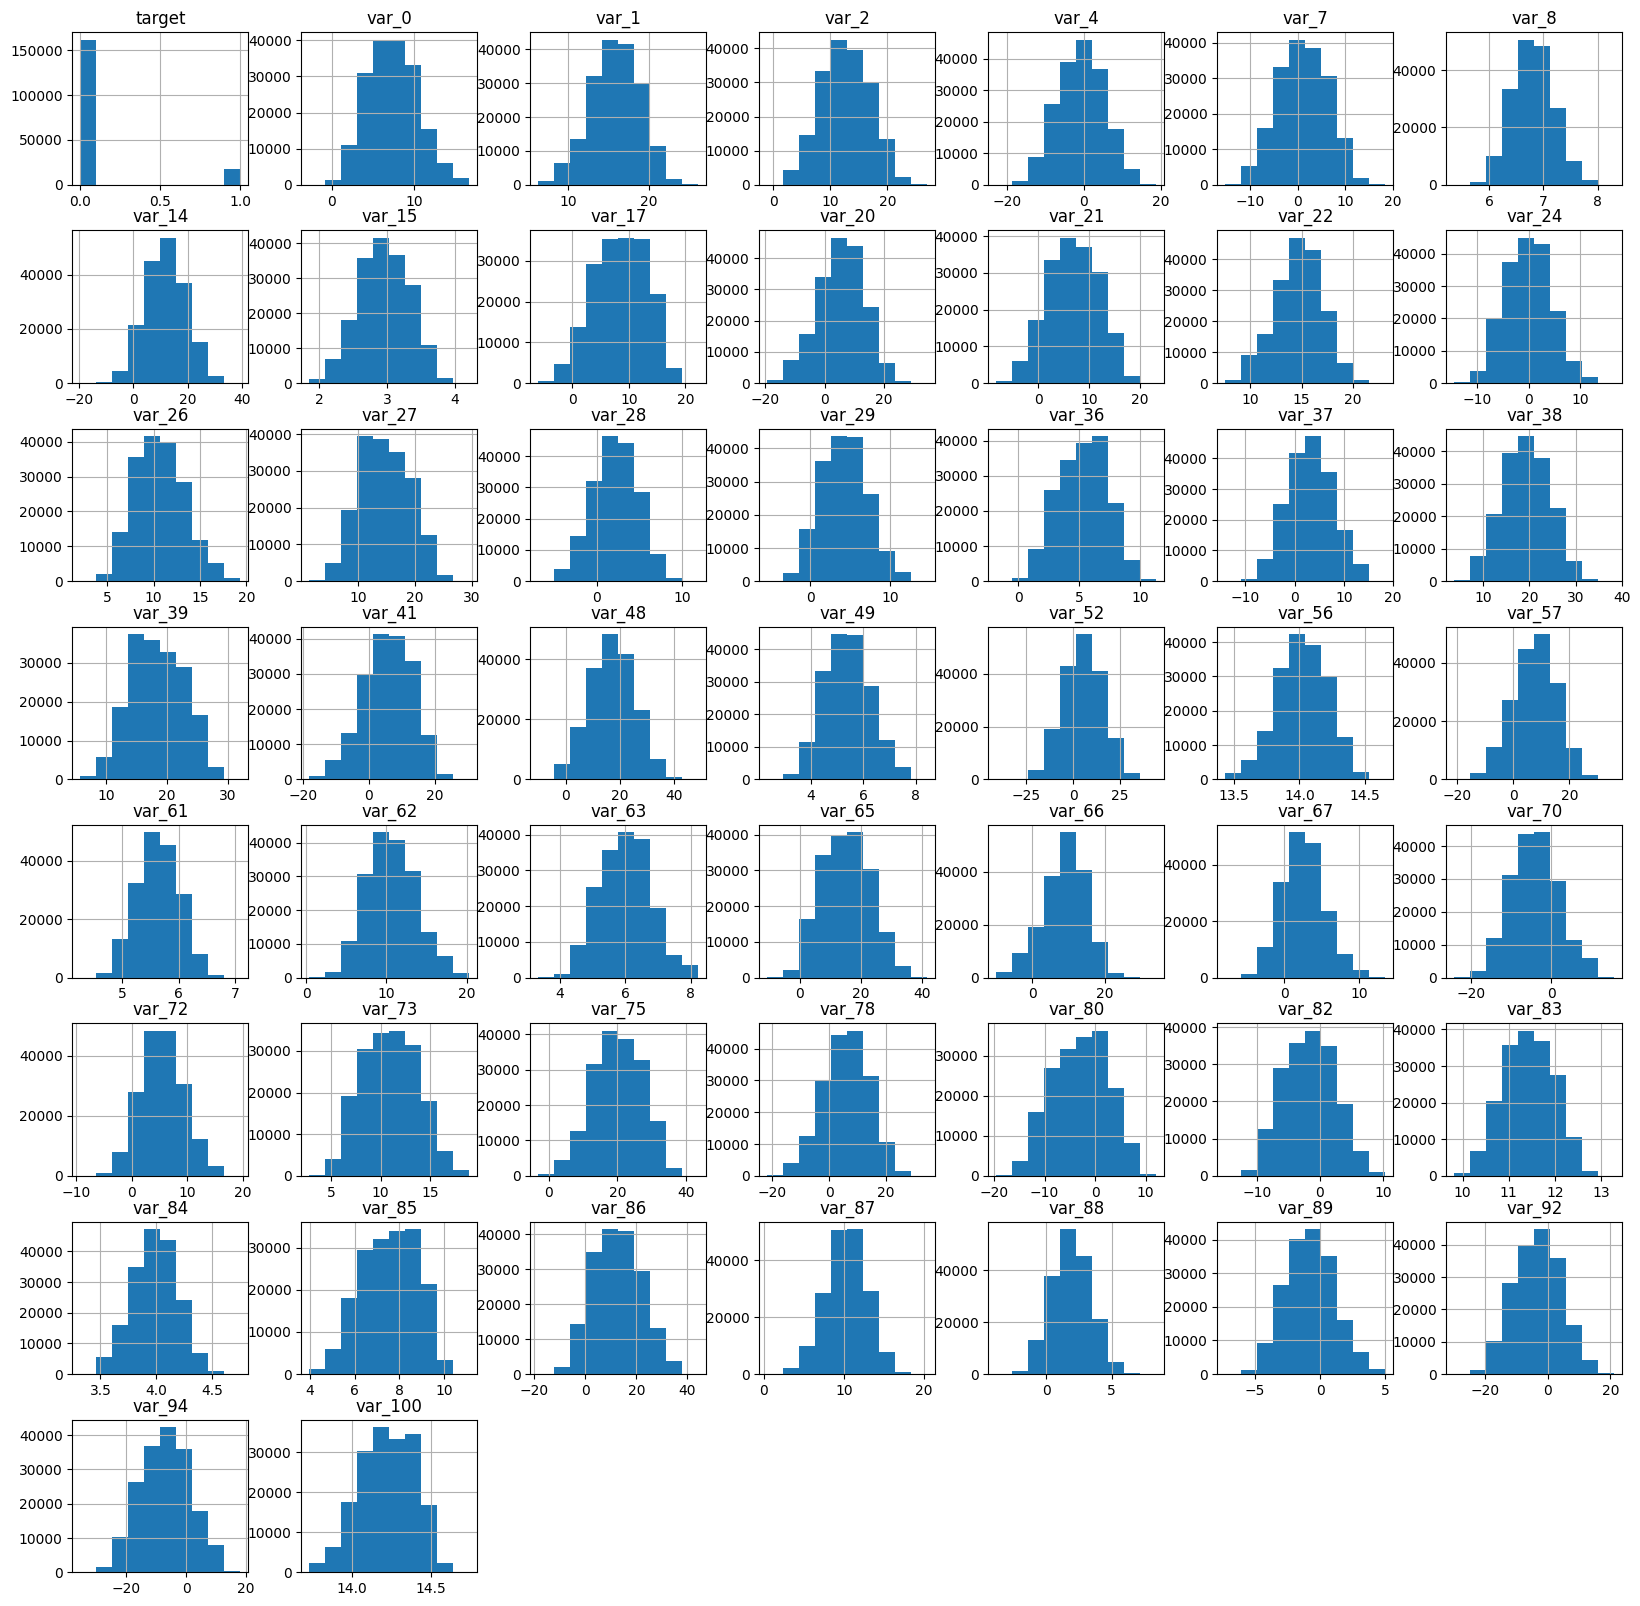

In [52]:
# Display a histogram
df.hist(figsize=(20, 20))

Text(0, 0.5, 'Count of Feature Values (in hundreds)')

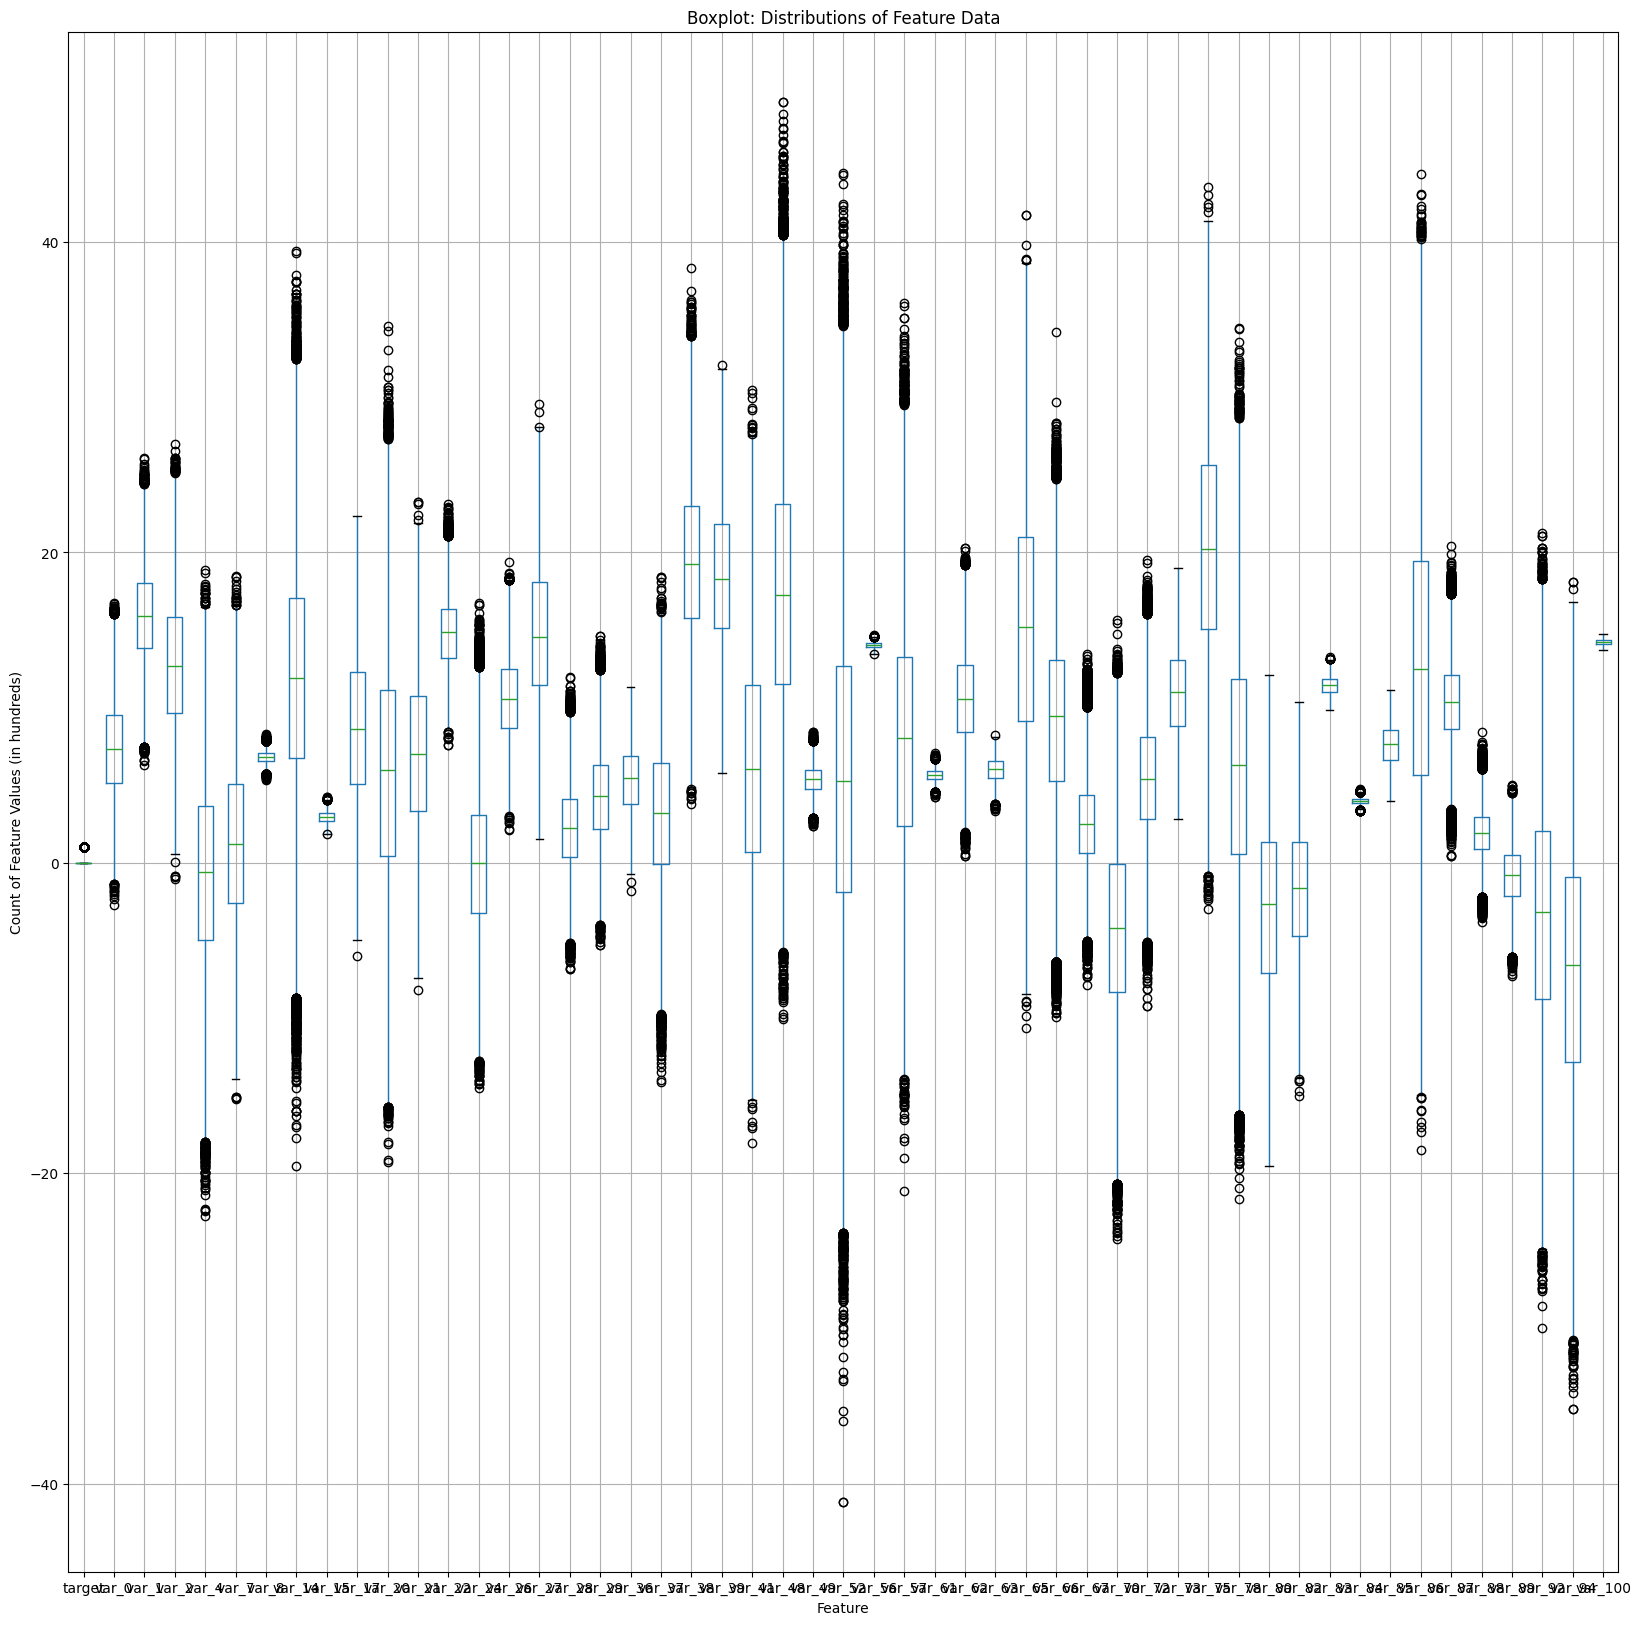

In [53]:
# display a boxplot
df.boxplot(figsize=(20, 20))
plt.title("Boxplot: Distributions of Feature Data")
plt.xlabel("Feature")
plt.ylabel("Count of Feature Values (in hundreds)")

#### 8. Check the correlation values between all **feature columns** to ensure there are no substantial correlations between features. This is important to support the decision to classify the ‘target’ using Naïve Bayes.



In [54]:
# column correlations
column_correlations = df.corr()
column_correlations

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
target,1.000000,0.045506,-0.051718,-0.046433,0.041593,-0.041987,0.052457,0.045281,-0.057373,-0.054375,...,-0.052324,-0.053733,-0.042073,0.047543,-0.063871,-0.042765,0.059306,0.040520,0.049072,-0.047005
var_0,0.045506,1.000000,-0.000892,-0.000225,-0.000269,-0.001320,0.002949,0.002901,-0.007758,-0.002799,...,-0.004960,-0.005451,-0.000716,0.004577,-0.004664,-0.001088,0.000236,0.001668,0.001837,0.001475
var_1,-0.051718,-0.000892,1.000000,0.006064,-0.000821,0.000783,-0.007127,-0.006180,-0.002585,-0.001663,...,0.004265,0.002411,0.001484,-0.003859,-0.000485,0.003141,-0.006188,0.000071,-0.003682,0.003964
var_2,-0.046433,-0.000225,0.006064,1.000000,-0.003427,-0.000108,-0.001809,-0.002786,-0.001177,0.006360,...,0.004890,0.002240,0.001980,-0.001161,0.003921,0.002087,-0.004422,-0.003418,-0.001565,0.002418
var_4,0.041593,-0.000269,-0.000821,-0.003427,1.000000,-0.002750,0.003347,0.001377,-0.004732,-0.001814,...,0.000657,-0.005267,-0.004266,-0.004179,-0.004211,-0.002330,0.000254,0.001090,-0.000468,-0.002807
var_7,-0.041987,-0.001320,0.000783,-0.000108,-0.002750,1.000000,-0.003199,-0.003588,0.002329,0.004282,...,-0.000412,0.003262,0.002574,-0.001824,0.001186,0.002811,0.001306,0.000236,-0.000568,0.004575
var_8,0.052457,0.002949,-0.007127,-0.001809,0.003347,-0.003199,1.000000,0.003472,-0.003858,-0.002727,...,-0.008394,-0.004254,-0.002446,0.001117,-0.003713,-0.003929,0.003837,0.003422,0.003204,0.000821
var_14,0.045281,0.002901,-0.006180,-0.002786,0.001377,-0.003588,0.003472,1.000000,-0.007115,-0.004249,...,-0.002214,-0.002179,-0.003054,-0.000160,-0.000504,-0.004046,0.003136,0.005715,0.001501,-0.000106
var_15,-0.057373,-0.007758,-0.002585,-0.001177,-0.004732,0.002329,-0.003858,-0.007115,1.000000,0.002467,...,0.000581,0.006633,0.004569,-0.001573,0.003251,0.003066,-0.001541,-0.003719,-0.002825,0.004247
var_17,-0.054375,-0.002799,-0.001663,0.006360,-0.001814,0.004282,-0.002727,-0.004249,0.002467,1.000000,...,0.005578,0.001237,0.000210,-0.002714,0.004149,-0.002182,-0.002642,-0.001968,-0.004100,-0.000822


Text(70.72222222222221, 0.5, 'Features')

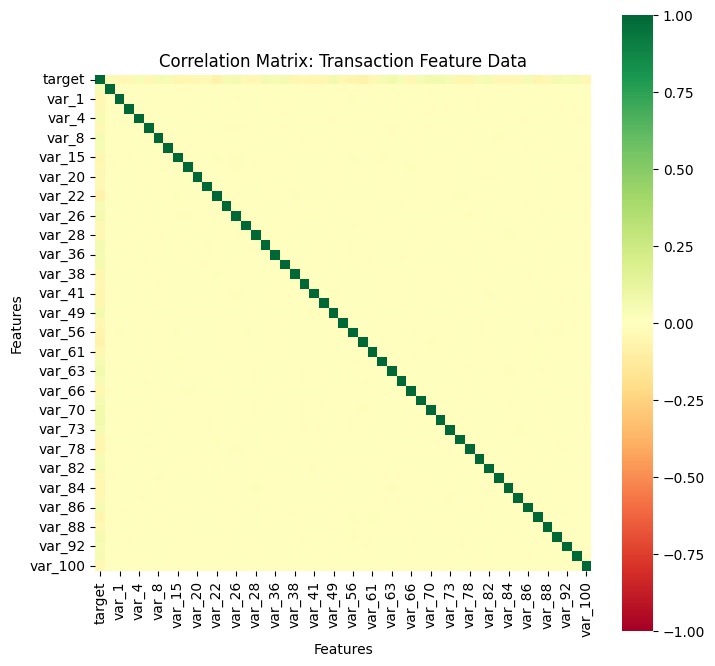

In [55]:
# Display correlation matrix
plt.figure(figsize = (8, 8))
sns.heatmap(
    column_correlations,
    annot = False,
    square = True,
    vmin = -1,
    vmax = 1,
    cmap = 'RdYlGn'
)
plt.title("Correlation Matrix: Transaction Feature Data")
plt.xlabel("Features")
plt.ylabel("Features")

#### 9. Create two data frames: one with all successful transactions, one with all unsuccessful transactions. **Make sure they are copies and not slices**.




In [56]:
# make successful (copy)
df_successful   = df[ df[target_col] == 1 ].copy()
df_successful

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
57,1.0,8.9078,12.1321,9.4707,-5.8102,0.4521,7.1264,15.6935,2.6980,4.3336,...,11.2059,4.0237,5.8905,12.4865,10.1419,2.3370,-3.1553,-12.6928,-3.0833,14.1895
125,1.0,6.2143,20.0990,23.5009,-0.8917,-3.9167,6.6863,21.4162,2.8672,6.4550,...,10.8110,3.9190,7.4971,35.7428,9.6149,2.2257,-0.5949,-9.4101,-15.6555,14.4514
151,1.0,8.9083,12.1117,18.0359,-4.9628,10.1135,6.8962,11.4553,2.6735,2.1990,...,11.6326,3.9193,5.0366,37.1453,17.0341,0.9987,-3.0163,-1.5409,-7.6389,14.1725
155,1.0,6.5612,13.9638,5.1980,12.1092,8.4874,6.4781,16.9541,2.0573,5.5008,...,11.2981,4.1316,7.2193,-1.8139,1.8190,2.5720,0.6780,6.4045,1.1754,14.1347
302,1.0,4.4616,9.7572,12.9317,7.6485,0.6382,5.8025,22.4577,3.0906,16.2501,...,11.5449,4.0001,9.0639,11.8805,9.4678,1.0561,-0.2107,9.8815,-2.9328,14.0933
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049783,1.0,3.1286,15.0751,21.3962,11.3161,-10.0493,6.3525,25.4931,2.6605,7.2691,...,10.9172,4.1120,4.6540,9.1151,7.8918,2.5714,1.0304,5.2623,-0.6030,14.1993
1049818,1.0,15.2934,17.5721,5.8949,-4.0233,5.8840,7.3892,11.3932,2.7062,6.9666,...,11.1665,3.9652,7.4879,-7.9060,10.7256,0.8941,-3.5967,6.3976,0.5778,14.5067
1049978,1.0,7.4751,17.0314,5.0834,-1.5220,-2.4913,6.7953,10.7764,2.9049,2.6145,...,11.6605,3.6716,8.5965,19.2145,8.2747,4.0945,-3.0127,2.9477,-2.3696,14.4122
1049983,1.0,5.2746,14.4095,17.7709,-2.9855,-0.8515,6.5097,11.5599,2.9677,0.0507,...,11.8870,3.7776,6.9876,3.3482,9.7469,-0.3425,-2.5684,14.5286,-5.4146,14.4388


In [57]:
# make unsuccessful (copy)
df_unsuccessful = df[ df[target_col] == 0 ].copy()
df_unsuccessful

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049988,0.0,10.7453,13.3217,15.4001,4.0421,1.3116,6.3990,13.9387,2.9627,13.6450,...,11.6062,3.9162,9.7054,15.2405,10.6480,0.5372,0.4014,4.8258,-8.2380,14.0328
1049990,0.0,7.9632,20.4650,10.7295,2.9322,5.0267,7.1953,10.0695,3.0732,11.0135,...,12.1000,4.2019,7.1249,14.6591,10.2705,3.5833,2.5588,10.4219,-19.7158,14.0582
1049993,0.0,5.0862,14.4785,17.3709,-2.4732,-2.5987,6.6798,3.0420,2.4057,18.2729,...,10.9960,3.9637,8.0217,11.0449,9.3100,1.0545,-2.8770,-2.8052,-13.7290,14.3794
1049997,0.0,8.9941,13.4127,3.9567,3.5744,1.6614,6.1486,12.0996,2.5439,10.2936,...,10.5067,4.0642,8.3381,17.9081,12.3357,2.6530,-1.2359,2.0836,-18.6168,14.0689


## Data Processing



Data Processing outlines the steps for building and training the models to be used in making predictions, executes them, records the results, and presents the results using graphs, charts, reports, etc. This can include accuracies of model predictions vs. real values, metrics (precision, recall, and f1-score), confusion matrices, histograms, and more.

This section also includes the process of splitting data into target and features, as well as balancing the data set via downsampling or other appropriate methods.

For this project, we present the results of three models using the Train Test Split method of cross-validation: Single CV, Multiple CV, and Balanced Multiple CV. For the balanced multiple CV, we balance the data set first using downsampling and then run the same training process again to compare models.

Finally, for each model we include a mean accuracy and histogram to display the obtained accuracies, a confusion matrix to compare true/false positives/negatives, and a classification report showing the metrics for that model (e.g., precision, recall, and f1-score).

### Single Cross-validation ( CV )



#### 10. Create two data sets: one with all the feature columns (everything except for Unnamed: 0, ID_code and target) and one with just the target. Make sure they are copies and not slices.  And make sure they are the correct dimensions.



In [58]:
# make target and features
target   = df[ target_col ].copy()
features = df.drop( columns = [target_col] ).copy()

In [59]:
# check target
target

,target
3,0.0
5,0.0
11,0.0
15,0.0
19,0.0
...,...
1049990,0.0
1049993,0.0
1049995,1.0
1049997,0.0


In [60]:
# check target value counts
target.value_counts()

,count
target,
0.0,161960
1.0,18040


In [61]:
# check target dimensions and type
type(target), target.shape, target.ndim

(pandas.core.series.Series, (180000,), 1)

In [62]:
# check features
features

,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,var_20,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
3,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,0.5878,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
5,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,6.5456,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
11,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,18.7893,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
15,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,1.1400,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
19,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,7.8002,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049990,7.9632,20.4650,10.7295,2.9322,5.0267,7.1953,10.0695,3.0732,11.0135,3.1549,...,12.1000,4.2019,7.1249,14.6591,10.2705,3.5833,2.5588,10.4219,-19.7158,14.0582
1049993,5.0862,14.4785,17.3709,-2.4732,-2.5987,6.6798,3.0420,2.4057,18.2729,3.9661,...,10.9960,3.9637,8.0217,11.0449,9.3100,1.0545,-2.8770,-2.8052,-13.7290,14.3794
1049995,11.3251,16.4148,20.5955,-6.3011,-6.8112,7.3226,14.9182,2.4579,14.7175,3.8858,...,11.2265,3.8431,8.2748,-7.8464,9.9774,1.7377,-1.7942,1.3921,-16.4925,14.4421
1049997,8.9941,13.4127,3.9567,3.5744,1.6614,6.1486,12.0996,2.5439,10.2936,2.0014,...,10.5067,4.0642,8.3381,17.9081,12.3357,2.6530,-1.2359,2.0836,-18.6168,14.0689


In [63]:
# check features dimensions and type
type(features), features.shape, features.ndim

(pandas.core.frame.DataFrame, (180000, 50), 2)

#### 11. Define an empty Gaussian Naïve Bayes model using Sklearn.



In [64]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### 12. Divide the two data sets you created in step #10 into training and testing subsets, i.e. train-test split.



In [65]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split( features, target, test_size = 0.25 )

#### 13. Train ( fit ) the model using the training subset of the dataset.



In [66]:
# Train ( fit ) the model
modelGNB.fit(X_train, y_train)

GaussianNB()

#### 14. Test the model ( predict ) using the testing subset of the dataset.



In [67]:
# Make predictions using the model
y_pred = modelGNB.predict(X_test)

#### 15. Calculate and report the accuracy.



In [68]:
# Calculate the accuracy
accuracy = metrics.accuracy_score(y_test, y_pred)
accuracy

0.9110444444444444

#### 16. Present a confusion matrix and heatmap



Text(0.5, 1.0, 'Confusion Matrix, Single CV')

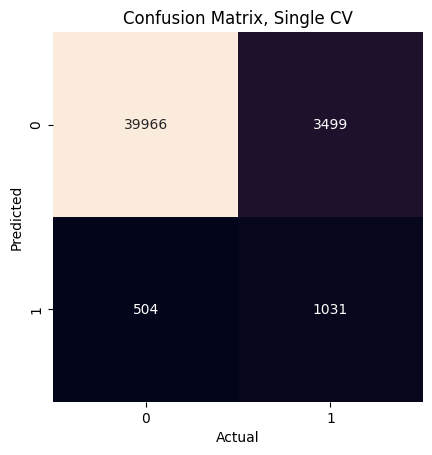

In [69]:
# Display confusion matrix
matrix = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion Matrix, Single CV')

#### 17. Present the results of a Classification Report (sklearn.metrics.classification_report).

In [70]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test, y_pred, output_dict = True, zero_division = 0)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

,precision,recall,f1-score,support
0.0,0.919498,0.987546,0.952308,40470.000000
1.0,0.671661,0.227594,0.339984,4530.000000
accuracy,0.911044,0.911044,0.911044,0.911044
macro avg,0.795580,0.607570,0.646146,45000.000000
weighted avg,0.894550,0.911044,0.890668,45000.000000


In [71]:
# Save variable values
X_train_SCV = X_train
X_test_SCV  = X_test
y_train_SCV = y_train
y_test_SCV  = y_test
y_pred_SCV  = y_pred



### Multiple Cross-validation ( CV )



#### 18. Perform a cross-validation loop and record the accuracy of your model during each iteration.



In [72]:
loop_count = 100

In [73]:
# Multiple CV loop

# Create array to hold results (accuracies)
n = loop_count
accuracies = np.zeros(n)

# Multiple CV loop
for i in range(n):

  # Train Test Split
  X_train, X_test, y_train, y_test = train_test_split(
      features,
      target,
      test_size = 0.25
  )

  # Create an empty GNB model
  modelGNB = GaussianNB()

  # Train ( fit ) the model
  modelGNB.fit(X_train, y_train)

  # Make predictions using the model
  y_pred = modelGNB.predict(X_test)

  # Calculate the accuracy and save to array
  accuracies[i] = metrics.accuracy_score(y_test, y_pred)

#### 19. Report the mean accuracy. How does it compare to the accuracy you calculated for the Single CV?



In [74]:
# Calculate mean of results (mean accuracy)
mean_accuracy = accuracies.mean()
mean_accuracy

np.float64(0.9110902222222224)

In [75]:
# Save variable values
X_train_MCV = X_train
X_test_MCV  = X_test
y_train_MCV = y_train
y_test_MCV  = y_test
y_pred_MCV  = y_pred

Analysis:

- Multiple Cross Validation (Multiple CV) gives a mean accuracy of 91.1% at 100 iterations and 91.1233% at 1000 iterations (so 91.1%).
- This is about the same as the result calculated for the Single CV, which in the previous pass was 91.2%.

#### 20. Plot a histogram of the accuracy scores you generated in your cross-validation loop. What do you notice about the distribution of accuracy scores?



Text(0, 0.5, 'Frequency')

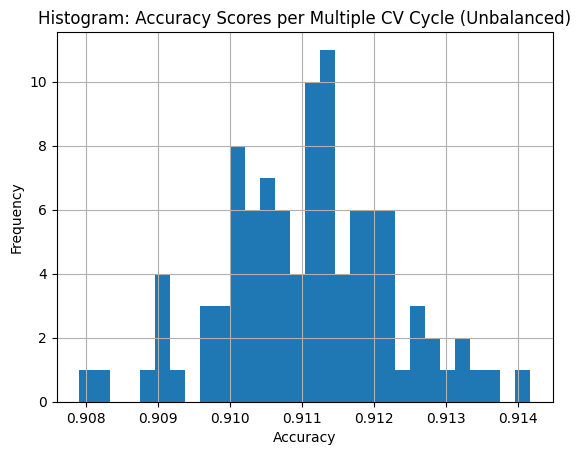

In [76]:
# Display a histogram of the results
pd.Series(accuracies).hist(bins = 30)
plt.title("Histogram: Accuracy Scores per Multiple CV Cycle (Unbalanced)")
plt.xlabel("Accuracy")
plt.ylabel("Frequency")

In [77]:
# --> The distribution of accuracy scores again mostly follows a normal distribution.

#### 21. Present a confusion matrix and heatmap



Text(0.5, 1.0, 'Confusion Matrix, Multiple CV')

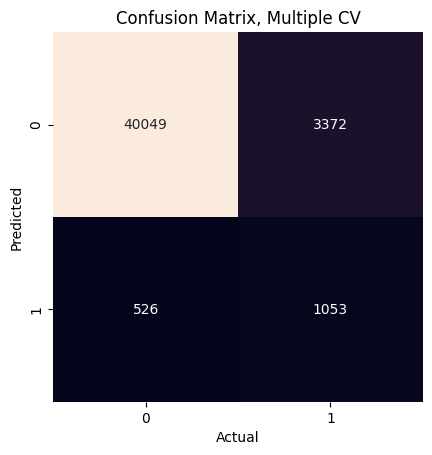

In [78]:
# Display a confusion matrix of final result of y_test and y_pred
matrix = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion Matrix, Multiple CV')

#### 22. Present the results of a Classification Report (sklearn.metrics.classification_report). What do you notice? That is, how do the different metrics compare to each other?



In [79]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test, y_pred, output_dict = True)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

,precision,recall,f1-score,support
0.0,0.922342,0.987036,0.953593,40575.000000
1.0,0.666878,0.237966,0.350766,4425.000000
accuracy,0.913378,0.913378,0.913378,0.913378
macro avg,0.794610,0.612501,0.652180,45000.000000
weighted avg,0.897221,0.913378,0.894315,45000.000000


Analysis:

- As with the smaller data set, the precision of this model for the large data set is good for negatives (no transaction) — right at 92% — but relatively poor when predicting positives (successful transactions), at 67.2%.
- These results worsen when looking at recall (true positives accuracy), which is 98.8% for negatives but only 23% for positives.
- Finally, the f1-score value for negatives is similarly high, at 95.3%, while for positives it is lower again, at 34.3%.
- This indicates the same pattern we saw with the smaller data set, where the model predicts negatives well but positives poorly when using highly unbalanced data — that is, with a binary target skewed 90-10.


### Balanced data set

The training data is very skewed towards non-successful transactions (about 90% of the training data has ‘target’==0).



#### 23. Remove enough non-successful transaction rows so that your remaining training data is 50%/50% split between successful and non-successful transactions. Hint: you can use the data frames you created in step #9.



In [80]:
# review value counts
df[target_col].value_counts()

,count
target,
0.0,161960
1.0,18040


In [81]:
# review head of successful
df_successful.head()

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
57,1.0,8.9078,12.1321,9.4707,-5.8102,0.4521,7.1264,15.6935,2.6980,4.3336,...,11.2059,4.0237,5.8905,12.4865,10.1419,2.3370,-3.1553,-12.6928,-3.0833,14.1895
125,1.0,6.2143,20.0990,23.5009,-0.8917,-3.9167,6.6863,21.4162,2.8672,6.4550,...,10.8110,3.9190,7.4971,35.7428,9.6149,2.2257,-0.5949,-9.4101,-15.6555,14.4514
151,1.0,8.9083,12.1117,18.0359,-4.9628,10.1135,6.8962,11.4553,2.6735,2.1990,...,11.6326,3.9193,5.0366,37.1453,17.0341,0.9987,-3.0163,-1.5409,-7.6389,14.1725
155,1.0,6.5612,13.9638,5.1980,12.1092,8.4874,6.4781,16.9541,2.0573,5.5008,...,11.2981,4.1316,7.2193,-1.8139,1.8190,2.5720,0.6780,6.4045,1.1754,14.1347
302,1.0,4.4616,9.7572,12.9317,7.6485,0.6382,5.8025,22.4577,3.0906,16.2501,...,11.5449,4.0001,9.0639,11.8805,9.4678,1.0561,-0.2107,9.8815,-2.9328,14.0933


In [82]:
# review head of unsuccessful
df_unsuccessful.head()

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275


- df_unsuccessful is the majority class. Therefore, we can undersample our unsuccessful dataframe as follows:

In [83]:
# preview output of undersampling (downsampling)
df_unsuccessful.sample(df_successful.shape[0]).head()

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
461003,0.0,4.3065,19.9364,9.4499,-4.8698,-1.2908,6.5652,-2.1759,3.5281,13.5214,...,10.8201,4.1624,9.0998,10.8520,5.8812,2.3307,-0.1325,6.4542,-5.2505,14.3263
884841,0.0,5.0556,17.1261,17.0183,-5.2834,-9.4669,6.4313,0.2263,2.5695,6.6702,...,11.0436,3.7663,9.8359,6.8194,9.5519,2.6233,-1.9457,-6.9736,8.0572,13.9169
860302,0.0,9.0973,16.4334,8.1800,-10.7641,3.9742,6.8883,19.2144,3.2083,10.0534,...,10.7495,3.9954,7.2074,17.1158,13.0236,2.3969,1.9778,1.4940,-13.9691,14.4075
455321,0.0,4.8297,14.5916,6.0108,-2.0403,6.3221,6.6307,11.3441,3.3397,13.6001,...,10.8146,4.1457,8.9376,7.8621,11.3557,-0.1042,0.7797,-9.4545,4.6309,14.3433
169218,0.0,5.4773,18.2703,14.6363,-2.8725,-3.0474,6.4264,7.9967,3.4656,6.7744,...,11.0863,3.7393,9.7774,3.6025,8.7849,1.4955,-2.4244,-2.0584,-9.8468,14.0275


In [84]:
# downsample
df_unsuccessful = df_unsuccessful.sample(df_successful.shape[0])

In [85]:
# check it
df_unsuccessful.head()

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
923158,0.0,5.8357,18.5700,13.1655,1.9348,-0.8988,6.7386,29.7168,3.2097,5.1595,...,11.0285,4.0794,7.6315,14.6431,10.3291,-0.3927,-0.7580,-1.7010,-10.2783,14.5004
476592,0.0,10.4524,17.4305,14.1980,10.2809,3.9396,7.1793,20.3938,3.1397,5.7823,...,11.7098,4.0687,7.0622,17.5531,11.1739,4.2767,-3.1527,-5.2427,-9.8770,14.2115
818350,0.0,6.5730,13.5767,9.2527,-5.8721,5.4798,6.8338,2.0938,2.9174,9.5018,...,10.9557,3.8436,7.6960,18.5137,11.8322,2.5258,-0.0323,-0.8623,-18.4885,14.2002
749089,0.0,4.0651,16.5166,17.4270,-3.4276,4.6942,6.7823,10.3582,3.3657,8.7163,...,11.8493,4.1288,5.8040,17.7423,9.7869,3.0220,0.0085,-5.1092,4.3338,14.5188
312446,0.0,11.4558,17.6127,17.4358,-8.5617,6.9541,6.7706,9.3390,3.3789,13.7949,...,10.9152,4.0098,7.4392,1.3812,4.7927,4.7576,-2.2979,-5.5215,-0.2063,14.2831


In [86]:
# check sizes to ensure they match
df_successful.shape[0], df_unsuccessful.shape[0]

(18040, 18040)

In [87]:
# Combine data frames
df = pd.concat([df_unsuccessful, df_successful], ignore_index = True)
df

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
0,0.0,5.8357,18.5700,13.1655,1.9348,-0.8988,6.7386,29.7168,3.2097,5.1595,...,11.0285,4.0794,7.6315,14.6431,10.3291,-0.3927,-0.7580,-1.7010,-10.2783,14.5004
1,0.0,10.4524,17.4305,14.1980,10.2809,3.9396,7.1793,20.3938,3.1397,5.7823,...,11.7098,4.0687,7.0622,17.5531,11.1739,4.2767,-3.1527,-5.2427,-9.8770,14.2115
2,0.0,6.5730,13.5767,9.2527,-5.8721,5.4798,6.8338,2.0938,2.9174,9.5018,...,10.9557,3.8436,7.6960,18.5137,11.8322,2.5258,-0.0323,-0.8623,-18.4885,14.2002
3,0.0,4.0651,16.5166,17.4270,-3.4276,4.6942,6.7823,10.3582,3.3657,8.7163,...,11.8493,4.1288,5.8040,17.7423,9.7869,3.0220,0.0085,-5.1092,4.3338,14.5188
4,0.0,11.4558,17.6127,17.4358,-8.5617,6.9541,6.7706,9.3390,3.3789,13.7949,...,10.9152,4.0098,7.4392,1.3812,4.7927,4.7576,-2.2979,-5.5215,-0.2063,14.2831
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36075,1.0,3.1286,15.0751,21.3962,11.3161,-10.0493,6.3525,25.4931,2.6605,7.2691,...,10.9172,4.1120,4.6540,9.1151,7.8918,2.5714,1.0304,5.2623,-0.6030,14.1993
36076,1.0,15.2934,17.5721,5.8949,-4.0233,5.8840,7.3892,11.3932,2.7062,6.9666,...,11.1665,3.9652,7.4879,-7.9060,10.7256,0.8941,-3.5967,6.3976,0.5778,14.5067
36077,1.0,7.4751,17.0314,5.0834,-1.5220,-2.4913,6.7953,10.7764,2.9049,2.6145,...,11.6605,3.6716,8.5965,19.2145,8.2747,4.0945,-3.0127,2.9477,-2.3696,14.4122
36078,1.0,5.2746,14.4095,17.7709,-2.9855,-0.8515,6.5097,11.5599,2.9677,0.0507,...,11.8870,3.7776,6.9876,3.3482,9.7469,-0.3425,-2.5684,14.5286,-5.4146,14.4388


In [88]:
# check value counts to make sure target successful and unsuccessful counts are equal
df[target_col].value_counts()

,count
target,
0.0,18040
1.0,18040


In [89]:
# make a backup
df_bak5 = df.copy()
df_bak5

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
0,0.0,5.8357,18.5700,13.1655,1.9348,-0.8988,6.7386,29.7168,3.2097,5.1595,...,11.0285,4.0794,7.6315,14.6431,10.3291,-0.3927,-0.7580,-1.7010,-10.2783,14.5004
1,0.0,10.4524,17.4305,14.1980,10.2809,3.9396,7.1793,20.3938,3.1397,5.7823,...,11.7098,4.0687,7.0622,17.5531,11.1739,4.2767,-3.1527,-5.2427,-9.8770,14.2115
2,0.0,6.5730,13.5767,9.2527,-5.8721,5.4798,6.8338,2.0938,2.9174,9.5018,...,10.9557,3.8436,7.6960,18.5137,11.8322,2.5258,-0.0323,-0.8623,-18.4885,14.2002
3,0.0,4.0651,16.5166,17.4270,-3.4276,4.6942,6.7823,10.3582,3.3657,8.7163,...,11.8493,4.1288,5.8040,17.7423,9.7869,3.0220,0.0085,-5.1092,4.3338,14.5188
4,0.0,11.4558,17.6127,17.4358,-8.5617,6.9541,6.7706,9.3390,3.3789,13.7949,...,10.9152,4.0098,7.4392,1.3812,4.7927,4.7576,-2.2979,-5.5215,-0.2063,14.2831
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36075,1.0,3.1286,15.0751,21.3962,11.3161,-10.0493,6.3525,25.4931,2.6605,7.2691,...,10.9172,4.1120,4.6540,9.1151,7.8918,2.5714,1.0304,5.2623,-0.6030,14.1993
36076,1.0,15.2934,17.5721,5.8949,-4.0233,5.8840,7.3892,11.3932,2.7062,6.9666,...,11.1665,3.9652,7.4879,-7.9060,10.7256,0.8941,-3.5967,6.3976,0.5778,14.5067
36077,1.0,7.4751,17.0314,5.0834,-1.5220,-2.4913,6.7953,10.7764,2.9049,2.6145,...,11.6605,3.6716,8.5965,19.2145,8.2747,4.0945,-3.0127,2.9477,-2.3696,14.4122
36078,1.0,5.2746,14.4095,17.7709,-2.9855,-0.8515,6.5097,11.5599,2.9677,0.0507,...,11.8870,3.7776,6.9876,3.3482,9.7469,-0.3425,-2.5684,14.5286,-5.4146,14.4388


In [90]:
df = df_bak5.copy()
df

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
0,0.0,5.8357,18.5700,13.1655,1.9348,-0.8988,6.7386,29.7168,3.2097,5.1595,...,11.0285,4.0794,7.6315,14.6431,10.3291,-0.3927,-0.7580,-1.7010,-10.2783,14.5004
1,0.0,10.4524,17.4305,14.1980,10.2809,3.9396,7.1793,20.3938,3.1397,5.7823,...,11.7098,4.0687,7.0622,17.5531,11.1739,4.2767,-3.1527,-5.2427,-9.8770,14.2115
2,0.0,6.5730,13.5767,9.2527,-5.8721,5.4798,6.8338,2.0938,2.9174,9.5018,...,10.9557,3.8436,7.6960,18.5137,11.8322,2.5258,-0.0323,-0.8623,-18.4885,14.2002
3,0.0,4.0651,16.5166,17.4270,-3.4276,4.6942,6.7823,10.3582,3.3657,8.7163,...,11.8493,4.1288,5.8040,17.7423,9.7869,3.0220,0.0085,-5.1092,4.3338,14.5188
4,0.0,11.4558,17.6127,17.4358,-8.5617,6.9541,6.7706,9.3390,3.3789,13.7949,...,10.9152,4.0098,7.4392,1.3812,4.7927,4.7576,-2.2979,-5.5215,-0.2063,14.2831
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36075,1.0,3.1286,15.0751,21.3962,11.3161,-10.0493,6.3525,25.4931,2.6605,7.2691,...,10.9172,4.1120,4.6540,9.1151,7.8918,2.5714,1.0304,5.2623,-0.6030,14.1993
36076,1.0,15.2934,17.5721,5.8949,-4.0233,5.8840,7.3892,11.3932,2.7062,6.9666,...,11.1665,3.9652,7.4879,-7.9060,10.7256,0.8941,-3.5967,6.3976,0.5778,14.5067
36077,1.0,7.4751,17.0314,5.0834,-1.5220,-2.4913,6.7953,10.7764,2.9049,2.6145,...,11.6605,3.6716,8.5965,19.2145,8.2747,4.0945,-3.0127,2.9477,-2.3696,14.4122
36078,1.0,5.2746,14.4095,17.7709,-2.9855,-0.8515,6.5097,11.5599,2.9677,0.0507,...,11.8870,3.7776,6.9876,3.3482,9.7469,-0.3425,-2.5684,14.5286,-5.4146,14.4388


In [91]:
# make target and features again
target   = df[ target_col ].copy()
features = df.drop( columns = [target_col] ).copy()

In [92]:
target

,target
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
...,...
36075,1.0
36076,1.0
36077,1.0
36078,1.0


In [93]:
type(target), target.shape, target.ndim

(pandas.core.series.Series, (36080,), 1)

In [94]:
features

,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,var_20,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
0,5.8357,18.5700,13.1655,1.9348,-0.8988,6.7386,29.7168,3.2097,5.1595,10.4389,...,11.0285,4.0794,7.6315,14.6431,10.3291,-0.3927,-0.7580,-1.7010,-10.2783,14.5004
1,10.4524,17.4305,14.1980,10.2809,3.9396,7.1793,20.3938,3.1397,5.7823,11.5676,...,11.7098,4.0687,7.0622,17.5531,11.1739,4.2767,-3.1527,-5.2427,-9.8770,14.2115
2,6.5730,13.5767,9.2527,-5.8721,5.4798,6.8338,2.0938,2.9174,9.5018,10.4693,...,10.9557,3.8436,7.6960,18.5137,11.8322,2.5258,-0.0323,-0.8623,-18.4885,14.2002
3,4.0651,16.5166,17.4270,-3.4276,4.6942,6.7823,10.3582,3.3657,8.7163,3.8524,...,11.8493,4.1288,5.8040,17.7423,9.7869,3.0220,0.0085,-5.1092,4.3338,14.5188
4,11.4558,17.6127,17.4358,-8.5617,6.9541,6.7706,9.3390,3.3789,13.7949,1.0727,...,10.9152,4.0098,7.4392,1.3812,4.7927,4.7576,-2.2979,-5.5215,-0.2063,14.2831
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36075,3.1286,15.0751,21.3962,11.3161,-10.0493,6.3525,25.4931,2.6605,7.2691,7.3874,...,10.9172,4.1120,4.6540,9.1151,7.8918,2.5714,1.0304,5.2623,-0.6030,14.1993
36076,15.2934,17.5721,5.8949,-4.0233,5.8840,7.3892,11.3932,2.7062,6.9666,-6.1230,...,11.1665,3.9652,7.4879,-7.9060,10.7256,0.8941,-3.5967,6.3976,0.5778,14.5067
36077,7.4751,17.0314,5.0834,-1.5220,-2.4913,6.7953,10.7764,2.9049,2.6145,14.3567,...,11.6605,3.6716,8.5965,19.2145,8.2747,4.0945,-3.0127,2.9477,-2.3696,14.4122
36078,5.2746,14.4095,17.7709,-2.9855,-0.8515,6.5097,11.5599,2.9677,0.0507,6.9984,...,11.8870,3.7776,6.9876,3.3482,9.7469,-0.3425,-2.5684,14.5286,-5.4146,14.4388


In [95]:
type(features), features.shape, features.ndim

(pandas.core.frame.DataFrame, (36080, 50), 2)

#### 24. Repeat the multiple cross-validation process on this data set.



In [96]:
loop_count = 100 # reset the loop count for this loop

In [97]:
# Multiple CV loop

# Create array to hold results (accuracies)
n = loop_count
accuracies_balanced = np.zeros(n)

# Multiple CV loop
for i in range(n):

  # Train Test Split
  X_train, X_test, y_train, y_test = train_test_split( features, target, test_size = 0.25 )

  # Create an empty GNB model
  modelGNB = GaussianNB()

  # Train ( fit ) the model
  modelGNB.fit(X_train, y_train)

  # Make predictions using the model
  y_pred = modelGNB.predict(X_test)

  # Calculate the accuracy and save to array
  accuracies_balanced[i] = metrics.accuracy_score(y_test, y_pred)

#### 25. Report what your mean accuracy for this balanced data set.



In [98]:
# Calculate mean of results
mean_accuracy_balanced = accuracies_balanced.mean()
mean_accuracy_balanced

np.float64(0.7544822616407981)

In [99]:
# Save variable values
X_train_BAL = X_train
X_test_BAL  = X_test
y_train_BAL = y_train
y_test_BAL  = y_test
y_pred_BAL  = y_pred

#### 26. Plot a histogram of the accuracy scores you generated in your cross-validation loop. What do you notice about the distribution of accuracy scores?



Text(0, 0.5, 'Frequency')

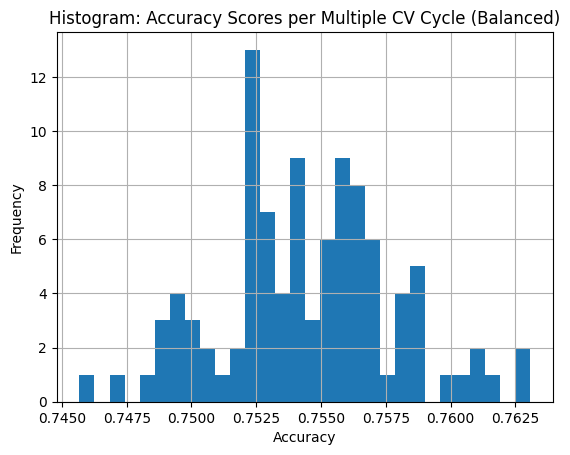

In [100]:
# Display a histogram of the results
pd.Series(accuracies_balanced).hist(bins = 30)
plt.title("Histogram: Accuracy Scores per Multiple CV Cycle (Balanced)")
plt.xlabel("Accuracy")
plt.ylabel("Frequency")

#### 27. Present a confusion matrix and heatmap



Text(0.5, 1.0, 'Confusion Matrix, Multiple CV (Balanced)')

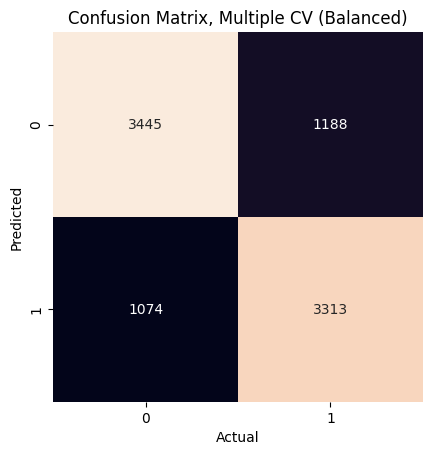

In [101]:
# Display a confusion matrix of final result of y_test and y_pred
matrix = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion Matrix, Multiple CV (Balanced)')

#### 28. Present the results of a Classification Report (sklearn.metrics.classification_report). What do you notice? That is, how do the different metrics compare to each other?



In [102]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test, y_pred, output_dict = True)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

,precision,recall,f1-score,support
0.0,0.743579,0.762337,0.752841,4519.000000
1.0,0.755186,0.736059,0.745500,4501.000000
accuracy,0.749224,0.749224,0.749224,0.749224
macro avg,0.749382,0.749198,0.749170,9020.000000
weighted avg,0.749371,0.749224,0.749178,9020.000000


Analysis:
- The precision, recall, and f1-score values for unsuccessful transactions substantially decreased (from around 91%, 95%, and 93% to 75%, 77%, and 76%, respectively).
- The precision, recally, and f1-score values for successful transactions dramatically increased (from around 66%, 22%, and 33% to 76%, 74%, and 75%, respectively).
- The accuracy decreased as well, from 90.7% to 75.5%.
- The proportion of false negatives and false positives is now about the same, at ~1000 / 9020 = 11%.
- The proportions of true positives and negatives are also around the same, at ~ 3500 / 9020 = 39%.

## Data Visualization



Data Visualization is fairly self-explanatory: Present visual representations of the data to show the results of the analysis and model performance.

Because this project requests visualizations throughout the process in each section, this final section includes a review of the results, focusing on the confusion matrices and classification reports.

#### 29. Compare the accuracy results of your multiple cross-validation with the whole training data and the balanced training data



In [103]:
accuracy

0.9110444444444444

In [104]:
float(mean_accuracy)

0.9110902222222224

In [105]:
float(mean_accuracy_balanced)

0.7544822616407981

#### 30. Present the confusion matrix and heatmap



Text(0, 0.5, 'Frequency')

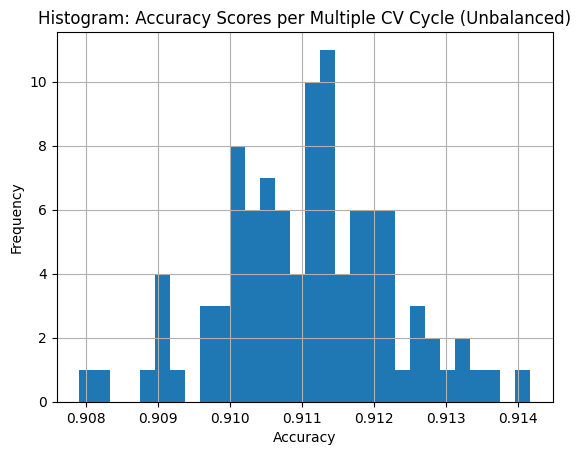

In [106]:
# Display a histogram of the results
pd.Series(accuracies).hist(bins = 30)
plt.title("Histogram: Accuracy Scores per Multiple CV Cycle (Unbalanced)")
plt.xlabel("Accuracy")
plt.ylabel("Frequency")

Text(0, 0.5, 'Frequency')

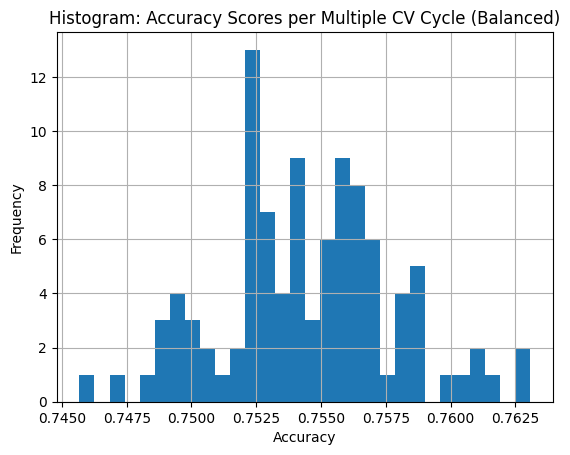

In [107]:
# Display a histogram of the results
pd.Series(accuracies_balanced).hist(bins = 30)
plt.title("Histogram: Accuracy Scores per Multiple CV Cycle (Balanced)")
plt.xlabel("Accuracy")
plt.ylabel("Frequency")

Text(0.5, 1.0, 'Confusion Matrix, Single CV')

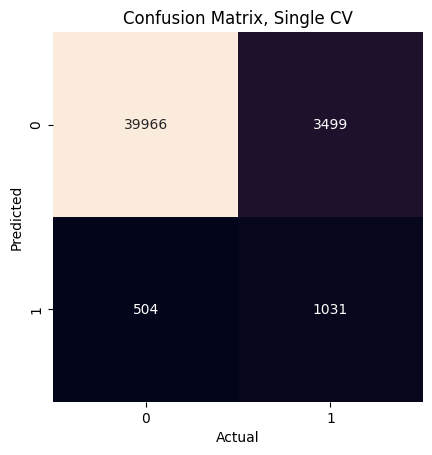

In [108]:
# Display a confusion matrix of final result of y_test and y_pred
matrix = metrics.confusion_matrix(y_test_SCV, y_pred_SCV)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion Matrix, Single CV')

Text(0.5, 1.0, 'Confusion Matrix, Multiple CV (Unbalanced)')

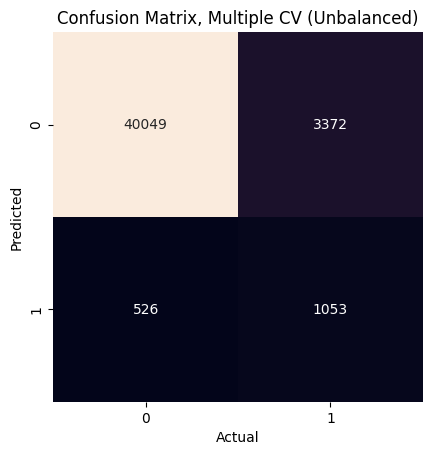

In [109]:
# Display a confusion matrix of final result of y_test and y_pred
matrix = metrics.confusion_matrix(y_test_MCV, y_pred_MCV)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion Matrix, Multiple CV (Unbalanced)')

Text(0.5, 1.0, 'Confusion Matrix, Multiple CV (Balanced)')

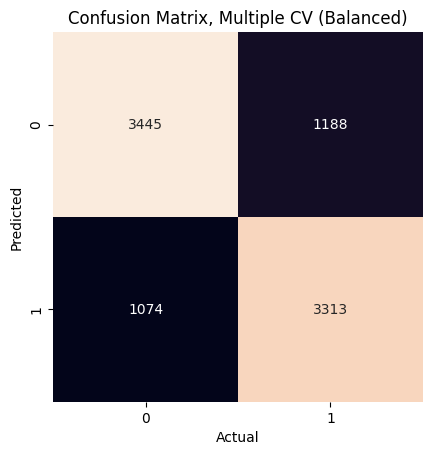

In [110]:
# Display a confusion matrix of final result of y_test and y_pred
matrix = metrics.confusion_matrix(y_test_BAL, y_pred_BAL)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion Matrix, Multiple CV (Balanced)')

#### 31. Present the results of your Classification Report (sklearn.metrics.classification_report)




In [111]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test_SCV, y_pred_SCV, output_dict = True)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

,precision,recall,f1-score,support
0.0,0.919498,0.987546,0.952308,40470.000000
1.0,0.671661,0.227594,0.339984,4530.000000
accuracy,0.911044,0.911044,0.911044,0.911044
macro avg,0.795580,0.607570,0.646146,45000.000000
weighted avg,0.894550,0.911044,0.890668,45000.000000


In [112]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test_MCV, y_pred_MCV, output_dict = True)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

,precision,recall,f1-score,support
0.0,0.922342,0.987036,0.953593,40575.000000
1.0,0.666878,0.237966,0.350766,4425.000000
accuracy,0.913378,0.913378,0.913378,0.913378
macro avg,0.794610,0.612501,0.652180,45000.000000
weighted avg,0.897221,0.913378,0.894315,45000.000000


In [113]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test_BAL, y_pred_BAL, output_dict = True)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

,precision,recall,f1-score,support
0.0,0.743579,0.762337,0.752841,4519.000000
1.0,0.755186,0.736059,0.745500,4501.000000
accuracy,0.749224,0.749224,0.749224,0.749224
macro avg,0.749382,0.749198,0.749170,9020.000000
weighted avg,0.749371,0.749224,0.749178,9020.000000


## Communicate the Results



Here we provide a brief outline of the main results of the processing — namely, the efficacy of the model, including its accuracy and associated metrics.

#### 32. Communicate the results of your analysis.


Conclusions:
- The mean accuracy for the balanced set was considerably lower than the accuracy and mean accuracy for the SingleCV and MultipleCV sets, at around ~75%.
- The precision of true negatives likewise decreased from around ~91% to ~75%.
- However, the precision of true positives has gone up, from around ~66% to ~75%.
- Even more significant, the recall of positives (ratio of true positives to total positives) has gone way up, from ~22% to ~75%.
- Percentage accuracy, recall, and f1-score of false positives, false negatives, true positives, and true negatives all about the same as each other.

Takeaways:
- The model's ability to predict negatives is now much lower than both the unbalanced model and random, at around 75%. This means it yields a correct value only 3 out of 4 times, which is not ideal.
- The tradeoff, however, is that the model's ability to predict positives is now much higher than unbalanced and random, making this model far more balanced.
- In this sense, the model is better at predicting all classes of the target, and might be considered a better model for transaction success.


Future Work:
- Other types of validation, e.g., K-Fold Cross Validation
- Other types of data set balancing (e.g., upsampling)
- Different models (such as Random Forest)

## Submit Final Project

#### 33. Save ( commit ) your finished Jupyter notebook to your Project 1 GitHub repo.

> Included here for checklist reference.